# Лабораторная работа №3
## Исследование алгоритма решающего дерева

**Цель работы:** исследовать решающие деревья для решения задач классификации и регрессии, оценить базовые модели `scikit-learn`, проверить гипотезы улучшения, самостоятельно реализовать алгоритм CART и сравнить результаты

В работе используются те же наборы данных, что и в ЛР1–ЛР2:

- **Классификация:** Breast Cancer Wisconsin (Diagnostic), определение злокачественности опухоли
- **Регрессия:** Wine Quality Red, прогнозирование экспертной оценки качества вина

## 1. Постановка задач и метрики

### 1.1. Классификация - Breast Cancer Wisconsin
Целевая переменная: `0` - malignant, `1` - benign. Для оценки используются Accuracy, F1-score (binary и macro), ROC-AUC, Recall и F1 для класса malignant, а также матрица ошибок. В медицинском контексте отдельно анализируется полнота обнаружения злокачественных случаев

### 1.2. Регрессия - Wine Quality Red
Целевая переменная - `quality`. Используются MAE, RMSE и R^2. Для MAE/RMSE меньшее значение лучше, для R^2 - большее

### 1.3. Особенности решающих деревьев
Деревья разбивают пространство признаков последовательностью пороговых правил. Для классификации качество разбиения оценивается критерием Gini или entropy, для регрессии - уменьшением квадратичной ошибки. В отличие от KNN и линейных моделей, деревья обычно не требуют стандартизации признаков. Для контроля переобучения исследуются `max_depth`, `min_samples_split` и `min_samples_leaf`

В этой ячейке импортируются библиотеки для подготовки данных, визуализации, обучения деревьев, подбора гиперпараметров и оценки качества. Фиксируется `RANDOM_STATE` для воспроизводимости экспериментов

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, recall_score,
    confusion_matrix, classification_report, RocCurveDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

Загружаются 2 набора данных. Для Breast Cancer используется встроенный датасет `scikit-learn`; Wine Quality Red загружается из UCI. Затем проверяются размеры, типы и распределения целевых переменных

In [2]:
cancer = load_breast_cancer()
X_clf = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_clf = pd.Series(cancer.target, name="target")

url_wine = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
wine = pd.read_csv(url_wine, sep=";")
X_reg = wine.drop(columns="quality")
y_reg = wine["quality"]

print("Breast Cancer:", X_clf.shape, y_clf.value_counts().sort_index().to_dict())
print("Wine Quality:", X_reg.shape, y_reg.value_counts().sort_index().to_dict())
display(wine.head())

Breast Cancer: (569, 30) {0: 212, 1: 357}
Wine Quality: (1599, 11) {3: 10, 4: 53, 5: 681, 6: 638, 7: 199, 8: 18}


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Графики показывают распределение классов в медицинском датасете и распределение оценок качества вина. Они помогают оценить баланс классов и особенности целевой переменной регрессии

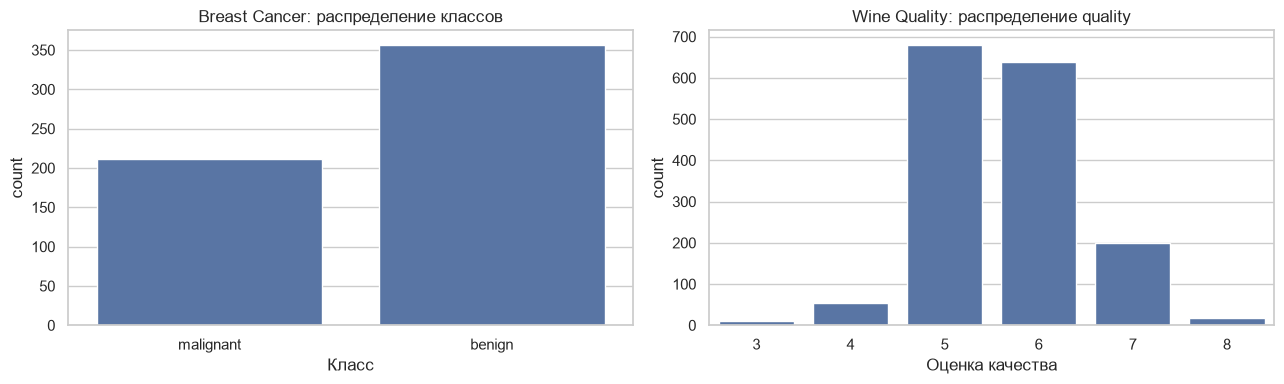

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=y_clf.map({0: "malignant", 1: "benign"}), ax=axes[0])
axes[0].set_title("Breast Cancer: распределение классов")
axes[0].set_xlabel("Класс")
sns.countplot(x=y_reg, ax=axes[1])
axes[1].set_title("Wine Quality: распределение quality")
axes[1].set_xlabel("Оценка качества")
plt.tight_layout()
plt.show()

Данные разделяются на обучающую и тестовую выборки в пропорции 80/20. Для классификации используется стратификация, сохраняющая соотношение классов. Тестовые данные не участвуют в подборе гиперпараметров

In [4]:
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

print("Classification:", X_clf_train.shape, X_clf_test.shape)
print("Regression:", X_reg_train.shape, X_reg_test.shape)

Classification: (455, 30) (114, 30)
Regression: (1279, 11) (320, 11)


## 2. Создание baseline и оценка качества

### 2.1. DecisionTreeClassifier - baseline

Обучается базовое дерево классификации с параметрами библиотеки по умолчанию. Рассчитываются предсказанные классы и вероятности, после чего вычисляются основные метрики, включая метрики для класса malignant

In [5]:
tree_clf_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_clf_base.fit(X_clf_train, y_clf_train)

y_clf_pred_base = tree_clf_base.predict(X_clf_test)
y_clf_proba_base = tree_clf_base.predict_proba(X_clf_test)[:, 1]

acc_clf_base = accuracy_score(y_clf_test, y_clf_pred_base)
f1_clf_base = f1_score(y_clf_test, y_clf_pred_base)
f1_macro_clf_base = f1_score(y_clf_test, y_clf_pred_base, average="macro")
roc_clf_base = roc_auc_score(y_clf_test, y_clf_proba_base)
recall_mal_base = recall_score(y_clf_test, y_clf_pred_base, pos_label=0)
f1_mal_base = f1_score(y_clf_test, y_clf_pred_base, pos_label=0)

print(f"Accuracy: {acc_clf_base:.4f}")
print(f"F1 binary: {f1_clf_base:.4f}")
print(f"F1 macro: {f1_macro_clf_base:.4f}")
print(f"ROC-AUC: {roc_clf_base:.4f}")
print(f"Recall malignant: {recall_mal_base:.4f}")
print(f"F1 malignant: {f1_mal_base:.4f}")
print(classification_report(y_clf_test, y_clf_pred_base, target_names=["malignant", "benign"]))

Accuracy: 0.9123
F1 binary: 0.9286
F1 macro: 0.9075
ROC-AUC: 0.9157
Recall malignant: 0.9286
F1 malignant: 0.8864
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



### 2.2. DecisionTreeRegressor - baseline

Обучается базовое дерево регрессии с настройками по умолчанию. Качество прогноза оценивается на тестовой выборке по MAE, RMSE и R^2

In [6]:
tree_reg_base = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_reg_base.fit(X_reg_train, y_reg_train)
y_reg_pred_base = tree_reg_base.predict(X_reg_test)

mae_reg_base = mean_absolute_error(y_reg_test, y_reg_pred_base)
rmse_reg_base = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_base))
r2_reg_base = r2_score(y_reg_test, y_reg_pred_base)

print(f"MAE: {mae_reg_base:.4f}")
print(f"RMSE: {rmse_reg_base:.4f}")
print(f"R^2: {r2_reg_base:.4f}")

MAE: 0.4625
RMSE: 0.7786
R^2: 0.0723


### 2.3. Диагностика baseline-моделей

Матрица ошибок показывает типы ошибок классификатора, а график фактических и предсказанных значений помогает оценить разброс ошибок регрессии. Также выводятся глубина и число листьев деревьев - характеристики их сложности

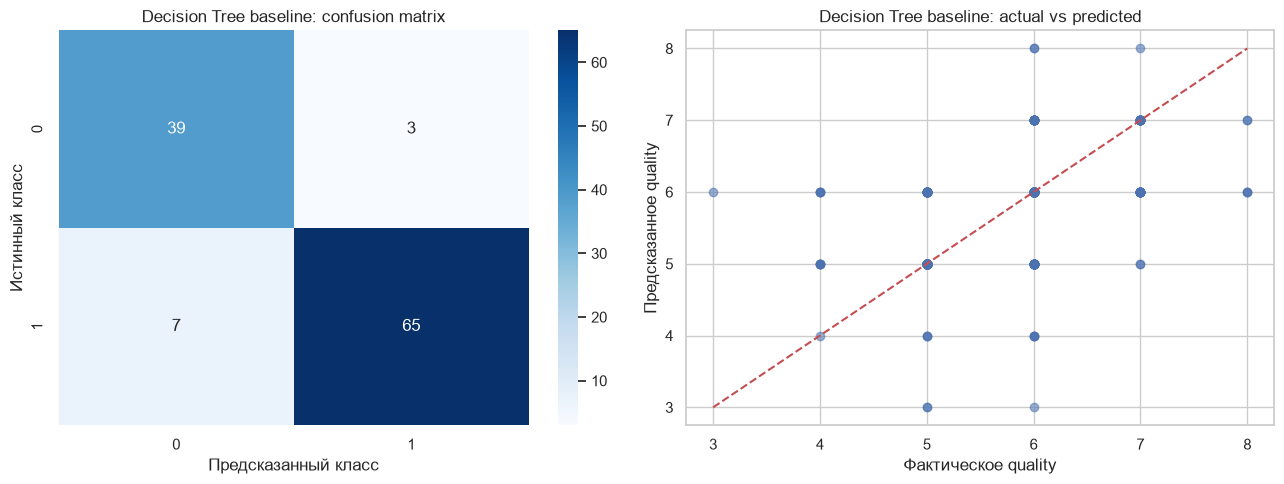

Classifier depth / leaves: 7 19
Regressor depth / leaves: 25 335


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_clf_test, y_clf_pred_base)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Decision Tree baseline: confusion matrix")
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Истинный класс")

axes[1].scatter(y_reg_test, y_reg_pred_base, alpha=0.55)
lims = [min(y_reg_test.min(), y_reg_pred_base.min()), max(y_reg_test.max(), y_reg_pred_base.max())]
axes[1].plot(lims, lims, "r--")
axes[1].set_title("Decision Tree baseline: actual vs predicted")
axes[1].set_xlabel("Фактическое quality")
axes[1].set_ylabel("Предсказанное quality")
plt.tight_layout()
plt.show()

print("Classifier depth / leaves:", tree_clf_base.get_depth(), tree_clf_base.get_n_leaves())
print("Regressor depth / leaves:", tree_reg_base.get_depth(), tree_reg_base.get_n_leaves())

## 3. Улучшение baseline

### 3.1. Гипотезы улучшения

**Для классификации:**
1. Ограничение `max_depth` уменьшит чрезмерную сложность дерева и риск переобучения
2. Увеличение `min_samples_leaf` не позволит строить листья на слишком малом числе наблюдений
3. Выбор критерия `gini` или `entropy` может изменить качество разбиений
4. Подбор параметров по `F1 macro` позволит учитывать оба класса, а не только accuracy

**Для регрессии:**
1. Ограничение глубины и размера листьев должно уменьшить дисперсию дерева
2. Подбор `min_samples_leaf` может сгладить прогнозы и улучшить обобщающую способность
3. Гиперпараметры подбираются по MAE на кросс-валидации

Стандартизация для деревьев не применяется: разбиения по порогам признаков в основном инвариантны к монотонному масштабированию. Важнее контролировать структуру дерева

### 3.2. Подбор гиперпараметров классификатора

`GridSearchCV` перебирает критерий разбиения, максимальную глубину и минимальное количество объектов для разбиения/листа. Используется пятиблочная стратифицированная кросс-валидация и `F1 macro`. Тестовая выборка не используется при выборе параметров

In [8]:
param_grid_clf = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_clf = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_clf,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)
grid_clf.fit(X_clf_train, y_clf_train)

print("Best params:", grid_clf.best_params_)
print("Best CV F1 macro:", round(grid_clf.best_score_, 4))

Best params: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best CV F1 macro: 0.9333


### 3.3. Подбор гиперпараметров регрессора

Для регрессии подбираются глубина дерева и минимальные размеры узла/листа. Критерий разбиения фиксируется как `squared_error`, а качество конфигураций оценивается по MAE с помощью пятиблочной кросс-валидации

In [9]:
param_grid_reg = {
    "max_depth": [None, 3, 5, 7, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 8]
}

grid_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid_reg,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)
grid_reg.fit(X_reg_train, y_reg_train)

print("Best params:", grid_reg.best_params_)
print("Best CV MAE:", round(-grid_reg.best_score_, 4))

Best params: {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV MAE: 0.4665


### 3.4. Оценка улучшенных sklearn-моделей

Лучшие конфигурации GridSearchCV обучены на всей обучающей выборке. Их качество оценивается на отложенной тестовой выборке, которая не участвовала в подборе параметров

In [10]:
tree_clf_improved = grid_clf.best_estimator_
y_clf_pred_improved = tree_clf_improved.predict(X_clf_test)
y_clf_proba_improved = tree_clf_improved.predict_proba(X_clf_test)[:, 1]

acc_clf_improved = accuracy_score(y_clf_test, y_clf_pred_improved)
f1_clf_improved = f1_score(y_clf_test, y_clf_pred_improved)
f1_macro_clf_improved = f1_score(y_clf_test, y_clf_pred_improved, average="macro")
roc_clf_improved = roc_auc_score(y_clf_test, y_clf_proba_improved)
recall_mal_improved = recall_score(y_clf_test, y_clf_pred_improved, pos_label=0)
f1_mal_improved = f1_score(y_clf_test, y_clf_pred_improved, pos_label=0)

tree_reg_improved = grid_reg.best_estimator_
y_reg_pred_improved = tree_reg_improved.predict(X_reg_test)
mae_reg_improved = mean_absolute_error(y_reg_test, y_reg_pred_improved)
rmse_reg_improved = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_improved))
r2_reg_improved = r2_score(y_reg_test, y_reg_pred_improved)

print("CLASSIFICATION")
print(f"Accuracy={acc_clf_improved:.4f}, F1={f1_clf_improved:.4f}, "
      f"F1 macro={f1_macro_clf_improved:.4f}, ROC-AUC={roc_clf_improved:.4f}")
print(f"Recall malignant={recall_mal_improved:.4f}, F1 malignant={f1_mal_improved:.4f}")
print("\nREGRESSION")
print(f"MAE={mae_reg_improved:.4f}, RMSE={rmse_reg_improved:.4f}, R^2={r2_reg_improved:.4f}")

CLASSIFICATION
Accuracy=0.9211, F1=0.9362, F1 macro=0.9164, ROC-AUC=0.9163
Recall malignant=0.9286, F1 malignant=0.8966

REGRESSION
MAE=0.5016, RMSE=0.8139, R^2=-0.0137


### 3.5. Сравнение baseline и improved

Таблицы показывают, изменилось ли качество после ограничения сложности деревьев и подбора гиперпараметров. Для классификации дополнительно сравниваются метрики обнаружения malignant

In [11]:
clf_baseline_vs_improved = pd.DataFrame([
    ["Decision Tree baseline", acc_clf_base, f1_clf_base, f1_macro_clf_base, roc_clf_base, recall_mal_base, f1_mal_base],
    ["Decision Tree improved", acc_clf_improved, f1_clf_improved, f1_macro_clf_improved, roc_clf_improved, recall_mal_improved, f1_mal_improved]
], columns=["Модель", "Accuracy", "F1 binary", "F1 macro", "ROC-AUC", "Recall malignant", "F1 malignant"])

reg_baseline_vs_improved = pd.DataFrame([
    ["Decision Tree baseline", mae_reg_base, rmse_reg_base, r2_reg_base],
    ["Decision Tree improved", mae_reg_improved, rmse_reg_improved, r2_reg_improved]
], columns=["Модель", "MAE", "RMSE", "R^2"])

display(clf_baseline_vs_improved.round(4))
display(reg_baseline_vs_improved.round(4))

,Модель,Accuracy,F1 binary,F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,Decision Tree baseline,0.9123,0.9286,0.9075,0.9157,0.9286,0.8864
1,Decision Tree improved,0.9211,0.9362,0.9164,0.9163,0.9286,0.8966


,Модель,MAE,RMSE,R^2
0,Decision Tree baseline,0.4625,0.7786,0.0723
1,Decision Tree improved,0.5016,0.8139,-0.0137


### 3.6. Визуализация улучшенных моделей

Сравниваются ROC-кривые baseline и improved классификаторов, матрица ошибок улучшенного классификатора и фактические/предсказанные значения регрессии

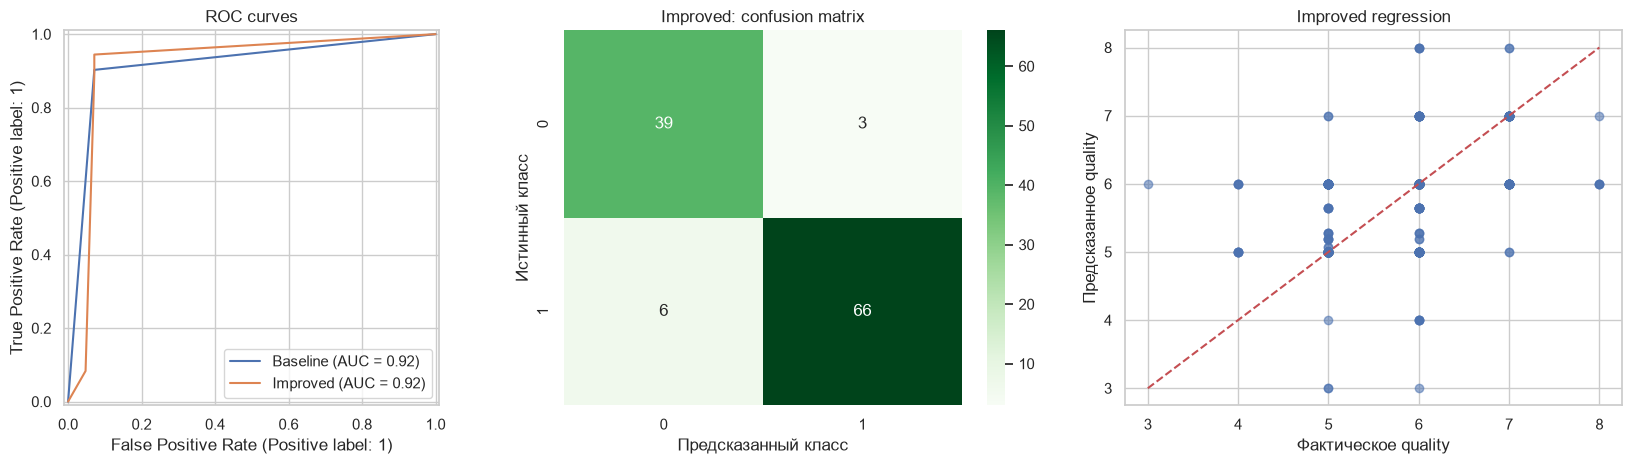

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_base, name="Baseline", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_improved, name="Improved", ax=axes[0])
axes[0].set_title("ROC curves")

sns.heatmap(confusion_matrix(y_clf_test, y_clf_pred_improved),
            annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Improved: confusion matrix")
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")

axes[2].scatter(y_reg_test, y_reg_pred_improved, alpha=0.55)
lims = [min(y_reg_test.min(), y_reg_pred_improved.min()),
        max(y_reg_test.max(), y_reg_pred_improved.max())]
axes[2].plot(lims, lims, "r--")
axes[2].set_title("Improved regression")
axes[2].set_xlabel("Фактическое quality")
axes[2].set_ylabel("Предсказанное quality")
plt.tight_layout()
plt.show()

## 4. Самостоятельная имплементация алгоритма CART

В этом разделе реализуется упрощённый алгоритм CART для классификации и регрессии без использования готовых классов `DecisionTreeClassifier` и `DecisionTreeRegressor` при обучении

Для классификации выбирается разбиение с минимальной взвешенной impurity (Gini или entropy). Для регрессии - разбиение с минимальной суммой квадратов отклонений внутри дочерних узлов. Для обоих типов дерева поддерживаются `max_depth`, `min_samples_split` и `min_samples_leaf`

Реализация предназначена для учебной демонстрации базового CART. Она не воспроизводит все оптимизации и дополнительные параметры промышленной реализации `scikit-learn`

В этой ячейке определяется собственный класс `MyDecisionTree`. Для каждого признака данные сортируются, затем перебираются допустимые пороги между соседними уникальными значениями. Выбирается разбиение с наименьшей взвешенной ошибкой; рекурсивное построение прекращается при достижении ограничений дерева

In [13]:
class MyDecisionTree:

    def __init__(self, task="classification", criterion=None, max_depth=None,
                 min_samples_split=2, min_samples_leaf=1):
        if task not in ("classification", "regression"):
            raise ValueError("task должен быть classification или regression")
        self.task = task
        self.criterion = criterion or ("gini" if task == "classification" else "squared_error")
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root_ = None

    def _impurity(self, y):
        if self.task == "classification":
            counts = np.bincount(y, minlength=len(self.classes_))
            p = counts[counts > 0] / len(y)
            if self.criterion == "entropy":
                return -np.sum(p * np.log2(p))
            return 1.0 - np.sum(p ** 2)
        return np.var(y)

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        parent_impurity = self._impurity(y)
        best = None
        best_score = parent_impurity

        for feature in range(n_features):
            order = np.argsort(X[:, feature], kind="mergesort")
            x_sorted = X[order, feature]
            y_sorted = y[order]

            positions = np.flatnonzero(x_sorted[:-1] < x_sorted[1:]) + 1
            positions = positions[
                (positions >= self.min_samples_leaf) &
                ((n_samples - positions) >= self.min_samples_leaf)
            ]
            if len(positions) == 0:
                continue

            if self.task == "classification":
                one_hot = np.eye(len(self.classes_), dtype=float)[y_sorted]
                cumulative = np.cumsum(one_hot, axis=0)
                total = cumulative[-1]
                left_counts = cumulative[positions - 1]
                right_counts = total - left_counts
                left_n = positions.astype(float)
                right_n = (n_samples - positions).astype(float)

                if self.criterion == "entropy":
                    def entropy(counts):
                        probs = counts / counts.sum(axis=1, keepdims=True)
                        terms = np.zeros_like(probs)
                        mask = probs > 0
                        terms[mask] = probs[mask] * np.log2(probs[mask])
                        return -terms.sum(axis=1)
                    left_imp = entropy(left_counts)
                    right_imp = entropy(right_counts)
                else:
                    left_p = left_counts / left_n[:, None]
                    right_p = right_counts / right_n[:, None]
                    left_imp = 1.0 - np.sum(left_p ** 2, axis=1)
                    right_imp = 1.0 - np.sum(right_p ** 2, axis=1)

                scores = (left_n * left_imp + right_n * right_imp) / n_samples
            else:
                cumulative_sum = np.cumsum(y_sorted)
                cumulative_sq = np.cumsum(y_sorted ** 2)
                total_sum = cumulative_sum[-1]
                total_sq = cumulative_sq[-1]

                left_n = positions.astype(float)
                right_n = (n_samples - positions).astype(float)
                left_sum = cumulative_sum[positions - 1]
                left_sq = cumulative_sq[positions - 1]
                right_sum = total_sum - left_sum
                right_sq = total_sq - left_sq

                left_sse = np.maximum(left_sq - left_sum ** 2 / left_n, 0)
                right_sse = np.maximum(right_sq - right_sum ** 2 / right_n, 0)
                scores = (left_sse + right_sse) / n_samples

            best_idx = int(np.argmin(scores))
            if scores[best_idx] < best_score - 1e-12:
                pos = int(positions[best_idx])
                threshold = (x_sorted[pos - 1] + x_sorted[pos]) / 2.0
                best_score = float(scores[best_idx])
                best = (feature, threshold)

        return best, best_score, parent_impurity

    def _build(self, X, y, depth):
        if self.task == "classification":
            counts = np.bincount(y, minlength=len(self.classes_))
            prediction = int(np.argmax(counts))
            value = counts / counts.sum()
        else:
            prediction = float(np.mean(y))
            value = prediction

        node = {"prediction": prediction, "value": value}
        stop = (
            len(y) < self.min_samples_split or
            len(np.unique(y)) == 1 or
            (self.max_depth is not None and depth >= self.max_depth)
        )
        if stop:
            return node

        split, child_score, parent_score = self._best_split(X, y)
        if split is None or child_score >= parent_score - 1e-12:
            return node

        feature, threshold = split
        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask
        if left_mask.sum() < self.min_samples_leaf or right_mask.sum() < self.min_samples_leaf:
            return node

        node.update({
            "feature": feature,
            "threshold": threshold,
            "left": self._build(X[left_mask], y[left_mask], depth + 1),
            "right": self._build(X[right_mask], y[right_mask], depth + 1)
        })
        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if self.task == "classification":
            self.classes_, y_encoded = np.unique(y, return_inverse=True)
            y_fit = y_encoded.astype(int)
        else:
            y_fit = y.astype(float)
        self.n_features_in_ = X.shape[1]
        self.root_ = self._build(X, y_fit, depth=0)
        return self

    def _predict_one(self, row, node):
        while "feature" in node:
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        return node

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        leaves = [self._predict_one(row, self.root_) for row in X]
        if self.task == "classification":
            return self.classes_[np.array([leaf["prediction"] for leaf in leaves], dtype=int)]
        return np.array([leaf["prediction"] for leaf in leaves], dtype=float)

    def predict_proba(self, X):
        if self.task != "classification":
            raise AttributeError("predict_proba доступен только для классификации")
        X = np.asarray(X, dtype=float)
        leaves = [self._predict_one(row, self.root_) for row in X]
        return np.vstack([leaf["value"] for leaf in leaves])

    def get_depth(self):
        def depth(node):
            if "feature" not in node:
                return 0
            return 1 + max(depth(node["left"]), depth(node["right"]))
        return depth(self.root_)

### 4.1. Собственные модели без улучшений (raw)

Собственные деревья обучаются на исходных признаках без ограничений глубины, кроме стандартных условий остановки. Для классификации рассчитываются Accuracy, F1, ROC-AUC и медицинские метрики; для регрессии - MAE, RMSE и R^2

In [14]:
my_tree_clf_raw = MyDecisionTree(task="classification").fit(X_clf_train, y_clf_train)
y_clf_pred_my_raw = my_tree_clf_raw.predict(X_clf_test)
y_clf_proba_my_raw = my_tree_clf_raw.predict_proba(X_clf_test)[:, list(my_tree_clf_raw.classes_).index(1)]

my_tree_reg_raw = MyDecisionTree(task="regression").fit(X_reg_train, y_reg_train)
y_reg_pred_my_raw = my_tree_reg_raw.predict(X_reg_test)

print("MyTree classifier raw")
print("Accuracy:", round(accuracy_score(y_clf_test, y_clf_pred_my_raw), 4))
print("F1 binary:", round(f1_score(y_clf_test, y_clf_pred_my_raw), 4))
print("F1 macro:", round(f1_score(y_clf_test, y_clf_pred_my_raw, average="macro"), 4))
print("ROC-AUC:", round(roc_auc_score(y_clf_test, y_clf_proba_my_raw), 4))
print("Recall malignant:", round(recall_score(y_clf_test, y_clf_pred_my_raw, pos_label=0), 4))
print("F1 malignant:", round(f1_score(y_clf_test, y_clf_pred_my_raw, pos_label=0), 4))
print("Depth:", my_tree_clf_raw.get_depth())

print("\nMyTree regressor raw")
print("MAE:", round(mean_absolute_error(y_reg_test, y_reg_pred_my_raw), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_raw)), 4))
print("R^2:", round(r2_score(y_reg_test, y_reg_pred_my_raw), 4))
print("Depth:", my_tree_reg_raw.get_depth())

MyTree classifier raw
Accuracy: 0.9123
F1 binary: 0.9286
F1 macro: 0.9075
ROC-AUC: 0.9157
Recall malignant: 0.9286
F1 malignant: 0.8864
Depth: 7

MyTree regressor raw
MAE: 0.4469
RMSE: 0.7726
R^2: 0.0867
Depth: 25


### 4.2. Собственные модели с техниками улучшенного baseline

Для собственных деревьев используются найденные GridSearchCV параметры контроля сложности. Масштабирование не добавляется, поскольку деревья принимают решения по порядку значений признаков и не нуждаются в стандартизации

In [15]:
best_params_my_clf = grid_clf.best_params_.copy()
best_params_my_reg = grid_reg.best_params_.copy()

my_tree_clf_improved = MyDecisionTree(
    task="classification", **best_params_my_clf
).fit(X_clf_train, y_clf_train)
y_clf_pred_my_improved = my_tree_clf_improved.predict(X_clf_test)
y_clf_proba_my_improved = my_tree_clf_improved.predict_proba(X_clf_test)[:, list(my_tree_clf_improved.classes_).index(1)]

my_tree_reg_improved = MyDecisionTree(
    task="regression", **best_params_my_reg
).fit(X_reg_train, y_reg_train)
y_reg_pred_my_improved = my_tree_reg_improved.predict(X_reg_test)

print("MyTree classifier improved")
print("Accuracy:", round(accuracy_score(y_clf_test, y_clf_pred_my_improved), 4))
print("F1 binary:", round(f1_score(y_clf_test, y_clf_pred_my_improved), 4))
print("F1 macro:", round(f1_score(y_clf_test, y_clf_pred_my_improved, average="macro"), 4))
print("ROC-AUC:", round(roc_auc_score(y_clf_test, y_clf_proba_my_improved), 4))
print("Recall malignant:", round(recall_score(y_clf_test, y_clf_pred_my_improved, pos_label=0), 4))
print("F1 malignant:", round(f1_score(y_clf_test, y_clf_pred_my_improved, pos_label=0), 4))

print("\nMyTree regressor improved")
print("MAE:", round(mean_absolute_error(y_reg_test, y_reg_pred_my_improved), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_improved)), 4))
print("R^2:", round(r2_score(y_reg_test, y_reg_pred_my_improved), 4))

MyTree classifier improved
Accuracy: 0.9211
F1 binary: 0.9362
F1 macro: 0.9164
ROC-AUC: 0.9163
Recall malignant: 0.9286
F1 malignant: 0.8966

MyTree regressor improved
MAE: 0.4681
RMSE: 0.7735
R^2: 0.0845


## 5. Сравнение всех моделей

Формируются итоговые таблицы для классификации и регрессии. Сравниваются baseline sklearn, improved sklearn, собственные реализации без ограничений и собственные реализации с параметрами улучшенного baseline

In [16]:
classification_results = pd.DataFrame([
    ["sklearn baseline", acc_clf_base, f1_clf_base, f1_macro_clf_base, roc_clf_base, recall_mal_base, f1_mal_base],
    ["sklearn improved", acc_clf_improved, f1_clf_improved, f1_macro_clf_improved, roc_clf_improved, recall_mal_improved, f1_mal_improved],
    ["MyTree raw", accuracy_score(y_clf_test, y_clf_pred_my_raw),
     f1_score(y_clf_test, y_clf_pred_my_raw), f1_score(y_clf_test, y_clf_pred_my_raw, average="macro"),
     roc_auc_score(y_clf_test, y_clf_proba_my_raw),
     recall_score(y_clf_test, y_clf_pred_my_raw, pos_label=0),
     f1_score(y_clf_test, y_clf_pred_my_raw, pos_label=0)],
    ["MyTree improved", accuracy_score(y_clf_test, y_clf_pred_my_improved),
     f1_score(y_clf_test, y_clf_pred_my_improved), f1_score(y_clf_test, y_clf_pred_my_improved, average="macro"),
     roc_auc_score(y_clf_test, y_clf_proba_my_improved),
     recall_score(y_clf_test, y_clf_pred_my_improved, pos_label=0),
     f1_score(y_clf_test, y_clf_pred_my_improved, pos_label=0)]
], columns=["Модель", "Accuracy", "F1 binary", "F1 macro", "ROC-AUC", "Recall malignant", "F1 malignant"])

regression_results = pd.DataFrame([
    ["sklearn baseline", mae_reg_base, rmse_reg_base, r2_reg_base],
    ["sklearn improved", mae_reg_improved, rmse_reg_improved, r2_reg_improved],
    ["MyTree raw", mean_absolute_error(y_reg_test, y_reg_pred_my_raw),
     np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_raw)), r2_score(y_reg_test, y_reg_pred_my_raw)],
    ["MyTree improved", mean_absolute_error(y_reg_test, y_reg_pred_my_improved),
     np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_improved)), r2_score(y_reg_test, y_reg_pred_my_improved)]
], columns=["Модель", "MAE", "RMSE", "R^2"])

display(classification_results.round(4))
display(regression_results.round(4))

,Модель,Accuracy,F1 binary,F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,sklearn baseline,0.9123,0.9286,0.9075,0.9157,0.9286,0.8864
1,sklearn improved,0.9211,0.9362,0.9164,0.9163,0.9286,0.8966
2,MyTree raw,0.9123,0.9286,0.9075,0.9157,0.9286,0.8864
3,MyTree improved,0.9211,0.9362,0.9164,0.9163,0.9286,0.8966


,Модель,MAE,RMSE,R^2
0,sklearn baseline,0.4625,0.7786,0.0723
1,sklearn improved,0.5016,0.8139,-0.0137
2,MyTree raw,0.4469,0.7726,0.0867
3,MyTree improved,0.4681,0.7735,0.0845


Графики позволяют сравнить ROC-кривые всех классификаторов и основные метрики регрессоров. Для MAE/RMSE меньшее значение лучше, для R^2 - большее

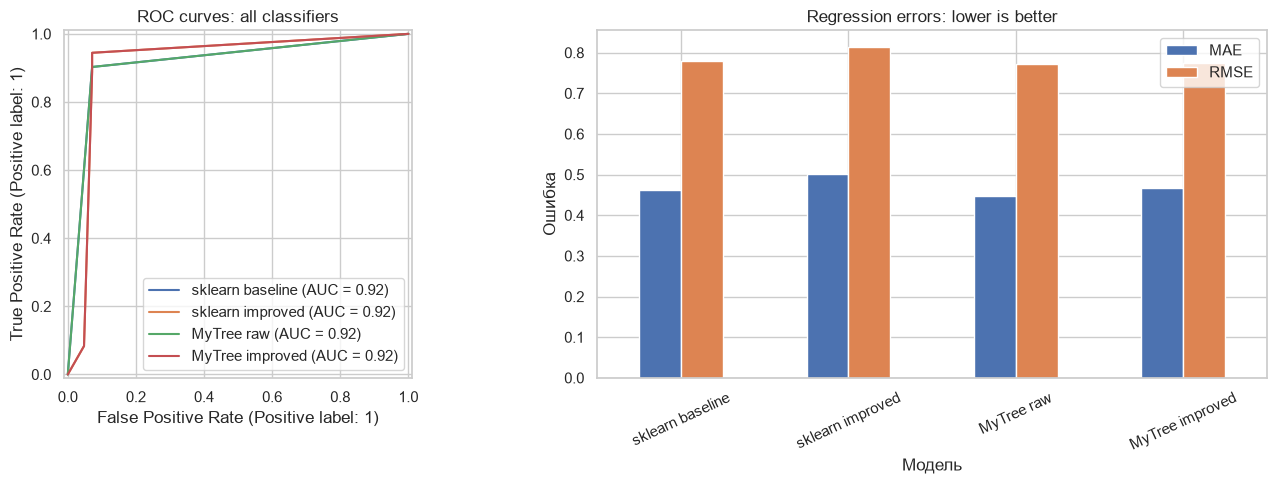

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_base, name="sklearn baseline", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_improved, name="sklearn improved", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_my_raw, name="MyTree raw", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_my_improved, name="MyTree improved", ax=axes[0])
axes[0].set_title("ROC curves: all classifiers")

reg_plot = regression_results.set_index("Модель")[["MAE", "RMSE"]]
reg_plot.plot(kind="bar", ax=axes[1])
axes[1].set_title("Regression errors: lower is better")
axes[1].set_ylabel("Ошибка")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### 5.1. Интерпретация дерева и важность признаков

Отображается ограниченная по глубине версия улучшенного классификационного дерева для интерпретируемости. Также выводятся наиболее важные признаки sklearn-моделей. Важности отражают вклад признаков в уменьшение impurity внутри конкретного дерева и не являются причинными эффектами

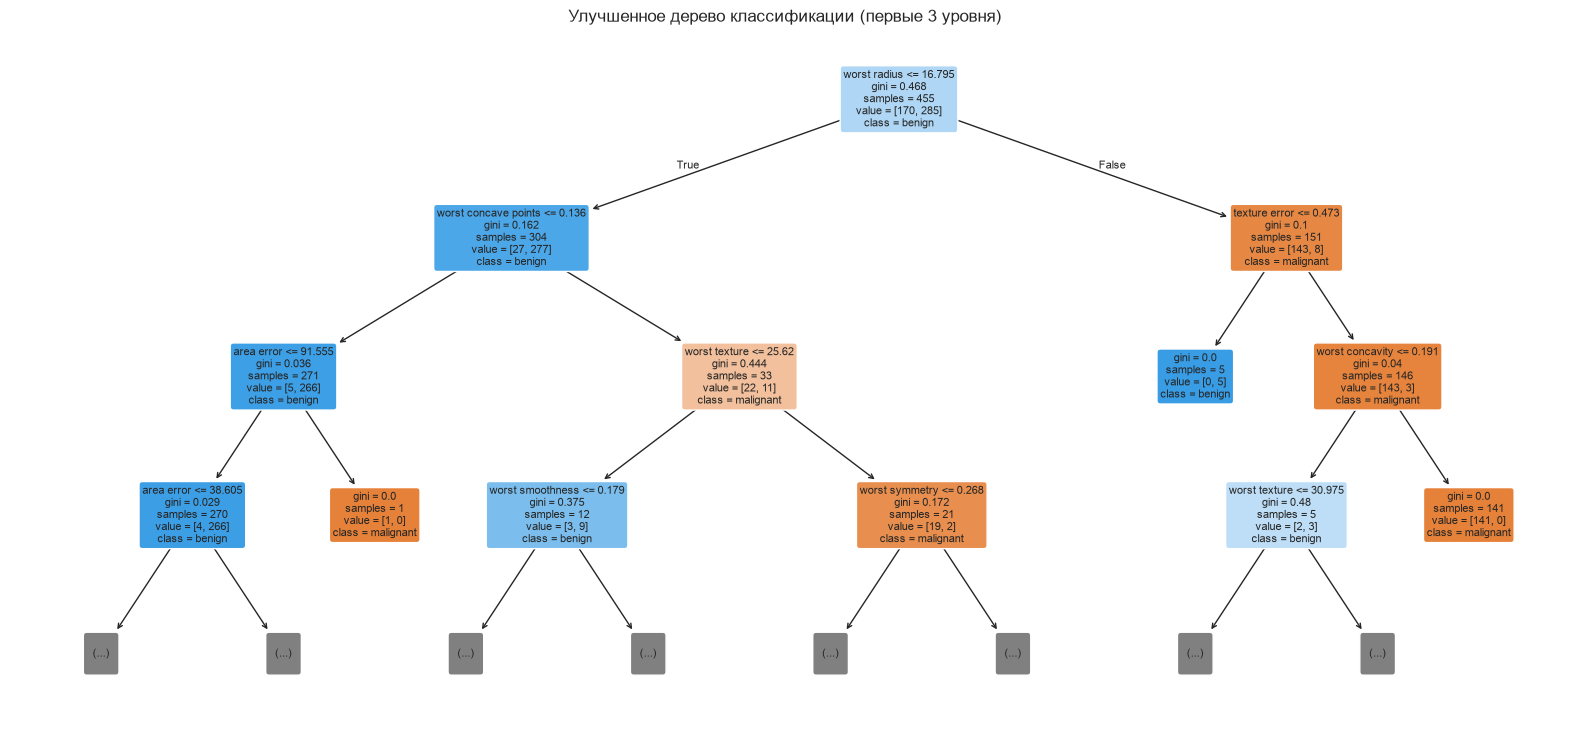

,importance
worst radius,0.718940
worst concave points,0.119597
texture error,0.054255
worst texture,0.043286
worst concavity,0.016819
worst smoothness,0.013062
area error,0.012451
worst symmetry,0.011058
worst area,0.008708
smoothness error,0.001824


,importance
alcohol,0.268158
sulphates,0.148955
volatile acidity,0.105626
total sulfur dioxide,0.079417
chlorides,0.076193
residual sugar,0.072356
density,0.071503
free sulfur dioxide,0.055773
fixed acidity,0.043884
citric acid,0.039249


In [18]:
plt.figure(figsize=(20, 9))
plot_tree(
    tree_clf_improved,
    feature_names=list(X_clf.columns),
    class_names=["malignant", "benign"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Улучшенное дерево классификации (первые 3 уровня)")
plt.show()

clf_importance = pd.Series(tree_clf_improved.feature_importances_, index=X_clf.columns)
display(clf_importance.sort_values(ascending=False).head(10).to_frame("importance"))

reg_importance = pd.Series(tree_reg_improved.feature_importances_, index=X_reg.columns)
display(reg_importance.sort_values(ascending=False).head(10).to_frame("importance"))

## 6. Выводы

### 6.1. Классификация

Для задачи определения злокачественности опухоли решающее дерево показало хорошее качество на тестовой выборке. Базовая модель получила Accuracy = 0.9123, F1 macro = 0.9075 и ROC-AUC = 0.9157. После подбора гиперпараметров (`criterion='gini', max_depth=5, min_samples_split=5, min_samples_leaf=1`) Accuracy выросла до 0.9211, F1 macro - до 0.9164, ROC-AUC - до 0.9163

Recall для класса malignant остался равен 0.9286: модель правильно обнаружила 39 из 42 злокачественных случаев, пропустив 3. F1 malignant вырос с 0.8864 до 0.8966. Следовательно, настройка дерева немного улучшила общий баланс качества, но не повысила полноту обнаружения злокачественных опухолей. Для медицинской задачи это ограничение особенно важно: одной Accuracy недостаточно, необходимо отдельно контролировать Recall malignant и анализировать ошибки

### 6.2. Регрессия

Для прогноза качества вина базовое дерево показало MAE = 0.4625, RMSE = 0.7786 и R^2 = 0.0723. GridSearchCV выбрал `max_depth=15, min_samples_split=2, min_samples_leaf=1` с лучшим CV MAE = 0.4665. Однако на тестовой выборке настроенная модель получила MAE = 0.5016, RMSE = 0.8139 и R^2 = -0.0137

Таким образом, на данном разбиении подбор параметров не улучшил регрессию: все три тестовые метрики стали хуже baseline. Отрицательный R^2 указывает, что качество предсказаний настроенного дерева на тестовой выборке оказалось хуже прогноза константой, равной среднему значению целевой переменной тестовой выборки. Это не ошибка вычислений, а результат эксперимента: лучшая конфигурация по кросс-валидации не обязательно оказывается лучшей на конкретной отложенной выборке

### 6.3. Самостоятельная реализация CART

Собственная реализация MyDecisionTree поддерживает классификацию и регрессию, критерии Gini/entropy для классификации, квадратичную ошибку для регрессии, а также ограничения `max_depth, min_samples_split` и `min_samples_leaf`

В классификации собственная реализация воспроизвела результаты sklearn-моделей на данном разбиении: raw-модель совпала с baseline, а модель с подобранными параметрами - с improved sklearn по приведённым метрикам. Это подтверждает согласованность реализации для проверенного набора данных и конфигураций

В регрессии собственная raw-модель получила MAE = 0.4469, RMSE = 0.7726 и R^2 = 0.0867, то есть немного превзошла sklearn baseline по всем трём метрикам. Собственная модель с параметрами GridSearchCV получила MAE = 0.4681, RMSE = 0.7735 и R^2 = 0.0845: по MAE она немного уступила sklearn baseline, но сохранила положительный R^2 и оказалась лучше настроенной sklearn-модели на этом тестовом разбиении. Небольшие различия между собственной реализацией и sklearn в регрессии допустимы: реализации могут выбирать разные разбиения при близких значениях критерия и по-разному разрешать равенство кандидатов

### 6.4. Общий итог

Эксперимент подтвердил, что решающие деревья подходят для задач классификации и регрессии, не требуют обязательной стандартизации признаков и позволяют интерпретировать решения через пороговые правила и важности признаков. Для классификации подбор гиперпараметров дал небольшое улучшение. Для регрессии улучшение по тестовым метрикам не подтвердилось, поэтому нельзя утверждать, что GridSearchCV повысил качество обеих моделей

Наиболее важные ограничения эксперимента: оценка выполнена на одном разбиении train/test; результаты могут зависеть от случайного разбиения и состава выборки. Важности признаков отражают вклад в снижение impurity конкретного дерева и не доказывают причинно-следственную связь. Для более надёжной оценки регрессии полезно дополнительно сравнить CV-результаты baseline и подобранной модели, расширить сетку min_samples_leaf и повторить оценку на нескольких разбиениях или с повторной кросс-валидацией

Итак, цель лабораторной работы достигнута: обучены baseline- и настроенные sklearn-деревья, реализован учебный вариант CART для классификации и регрессии, а результаты всех вариантов сопоставлены на одинаковых тестовых выборках